# [Evaluation](https://rhindottire.github.io/Data-Mining/dataProcess.html#evaluation)

Tahap ini meneliti angka yang dihasilkan Modeling. Empat lengan melaporkan
akurasi uji — 1.000 untuk dua rute TF-IDF, 0.975 untuk skip-gram bersih, dan
0.925 untuk lengan mentah tanpa pra-pemrosesan — dan evaluasi harus memutuskan
apakah angka itu dapat dipercaya, apakah menyembunyikan overfitting, dan
seberapa besar keyakinan yang layak dibawa aplikasi yang sudah disebar.
Setiap klaim di bawah ini direproduksi dari korpus dan model tersimpan di
`data/Web-Mining`; tidak ada yang dicrawl. Selain rangkaian inti, evaluasi
diperkuat dengan pemeriksaan stabilitas seed, kurva belajar empat lengan,
konsistensi CV, uji McNemar, kalibrasi, cakupan kosakata, laporan per kelas,
dan pengaruh outlier.

## 1. Evaluate Results

Evaluasi berangkat dari protokol persis yang ditetapkan Modeling: split
terstratifikasi 160/40 dengan seed 42, lalu empat lengan diukur pada 40 dokumen
tahanan yang sama. Pertanyaannya bukan hanya apakah angka itu terproduksi ulang,
tetapi mengapa begitu tinggi dan apa yang masih bisa salah.

### Reproduce Models

Hiperparameter pemenang dari Modeling diturunkan ulang di sini dan setiap lengan
di-fit pada split latih saja. Tidak ada apa pun di sisi uji yang disentuh selama
fitting.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = Path('..') / '..' / 'data' / 'Web-Mining'
CRISP = DATA_DIR / 'crisp-dm'
tokens = json.loads((CRISP / 'tokens.json').read_text(encoding='utf-8'))
labels_raw = pd.read_csv(CRISP / 'tfidf_docs.csv')

train_idx, test_idx = train_test_split(
    list(range(len(tokens['id']))),
    test_size=0.2,
    random_state=42,
    stratify=labels_raw['label'],
)
train_idx = np.array(train_idx, dtype=int)
test_idx = np.array(test_idx, dtype=int)
y_train = labels_raw['label'].iloc[train_idx]
y_test = labels_raw['label'].iloc[test_idx]
pd.Series(
    {
        'train documents': len(train_idx),
        'test documents': len(test_idx),
        'train label counts': str(y_train.value_counts().to_dict()),
        'test label counts': str(y_test.value_counts().to_dict()),
    },
    name='split',
)

train documents                                160
test documents                                  40
train label counts    {'finance': 80, 'sport': 80}
test label counts     {'finance': 20, 'sport': 20}
Name: split, dtype: object

Split terstratifikasi 160/40 yang sama dengan Modeling terproduksi ulang, dengan
label seimbang di kedua sisi.

In [2]:
import numpy as np
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline


def pool_documents(docs, model):
    pooled = []
    for doc in docs:
        words = [tok for sentence in doc for tok in sentence]
        vectors = [model.wv[word] for word in words if word in model.wv]
        pooled.append(
            np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)
        )
    return np.array(pooled)


stemmed_train = [tokens['tokens_stemmed'][i] for i in train_idx]
stemmed_test = [tokens['tokens_stemmed'][i] for i in test_idx]
tfidf = TfidfVectorizer(lowercase=False, token_pattern=r'(?u)\S+', min_df=2)
X_tf_train = tfidf.fit_transform(stemmed_train)
X_tf_test = tfidf.transform(stemmed_test)

mnb = MultinomialNB(alpha=0.5).fit(X_tf_train, y_train)
pca_gnb = make_pipeline(PCA(n_components=0.99), GaussianNB()).fit(
    X_tf_train.toarray(), y_train
)

sents_train = [s for i in train_idx for s in tokens['sentences'][i]]
w2v = Word2Vec(
    sents_train, vector_size=100, window=5, min_count=5, sg=1, seed=42, workers=1
)
docs_train = [tokens['sentences'][i] for i in train_idx]
docs_test = [tokens['sentences'][i] for i in test_idx]
X_wv_train = pool_documents(docs_train, w2v)
X_wv_test = pool_documents(docs_test, w2v)
gnb_wv = GaussianNB().fit(X_wv_train, y_train)

crawl_raw = pd.read_csv(DATA_DIR / 'crawling_detik.csv')
raw_by_id = {int(r.id): r.isi_berita for r in crawl_raw.itertuples()}


def raw_corpus(idx):
    return [[raw_by_id[int(tokens['id'][i])].split()] for i in idx]


raw_sentences = [raw_by_id[int(tokens['id'][i])].split() for i in train_idx]
w2v_plain = Word2Vec(
    raw_sentences, vector_size=100, window=5, min_count=5, sg=1, seed=42, workers=1
)
X_plain_train = pool_documents(raw_corpus(train_idx), w2v_plain)
X_plain_test = pool_documents(raw_corpus(test_idx), w2v_plain)
gnb_plain = GaussianNB().fit(X_plain_train, y_train)

arms = [
    ('TF-IDF + MultinomialNB', mnb, X_tf_train, X_tf_test),
    ('TF-IDF + PCA + GaussianNB', pca_gnb, X_tf_train.toarray(), X_tf_test.toarray()),
    ('Skip-gram + GaussianNB', gnb_wv, X_wv_train, X_wv_test),
    ('Plain skip-gram + GaussianNB', gnb_plain, X_plain_train, X_plain_test),
]
rows = []
for name, model, Xtr, Xte in arms:
    rows.append(
        {
            'representation': name,
            'train accuracy': round(model.score(Xtr, y_train), 4),
            'test accuracy': round(model.score(Xte, y_test), 4),
        }
    )
pd.DataFrame(rows)

,representation,train accuracy,test accuracy
0,TF-IDF + MultinomialNB,1.0000,1.000
1,TF-IDF + PCA + GaussianNB,1.0000,1.000
2,Skip-gram + GaussianNB,0.9938,0.975
3,Plain skip-gram + GaussianNB,0.9875,0.925


Reproduksi cocok dengan baris validasi Modeling: kedua rute TF-IDF mencetak
1.000 pada 40 dokumen uji, skip-gram bersih 0.975, dan lengan mentah tanpa
pra-pemrosesan 0.925. Model persis yang diterbitkan karenanya menjadi dasar
seluruh analisis di bawah.

### Baseline Comparison

Model tanpa usaha yang selalu menjawab kelas mayoritas mencetak 0.50 pada set
uji yang seimbang. Setiap lengan harus dibaca terhadap lantai itu: angka
mendekati 1.000 bermakna hanya jika jauh di atas baseline.

In [3]:
majority = y_test.value_counts().index[0]
base = float((y_test == majority).mean())
pd.Series(
    {
        'majority class': majority,
        'test accuracy': round(base, 3),
        'random guess': 0.5,
    },
    name='baseline',
)

majority class    finance
test accuracy         0.5
random guess          0.5
Name: baseline, dtype: object

Kelas mayoritas berada persis di 0.50 karena split dijaga seimbang, jadi
keunggulan yang harus dibuktikan setiap lengan adalah setengah skor penuh.

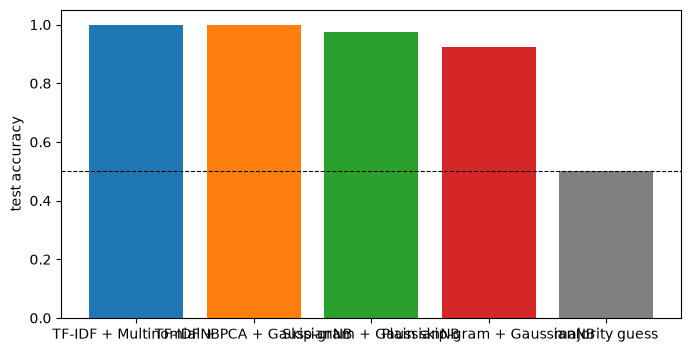

In [4]:
import matplotlib.pyplot as plt

test_scores = [arm[1].score(arm[3], y_test) for arm in arms]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    range(len(test_scores) + 1),
    test_scores + [base],
    tick_label=[arm[0] for arm in arms] + ['majority guess'],
    color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'gray'],
)
ax.set_ylim(0, 1.05)
ax.set_ylabel('test accuracy')
ax.axhline(0.5, color='black', ls='--', lw=0.8)
plt.show()

Empat lengan menggandakan baseline naif — bahkan lengan mentah yang paling
lemah sudah 0.925. Pertanyaannya karenanya bergeser dari apakah model
mengalahkan kebetulan — jelas ya — ke apakah angka yang nyaris sempurna itu
nyata atau menggelembung.

### Fold-Level CV

Modeling memilih konfigurasi dengan cross-validation, tetapi skor fold skip-gram
diukur pada vektor dari satu embedding yang dilatih pada seluruh split latih. Di
sini setiap fold me-refit vectorizer, PCA, dan model Word2Vec — bersih maupun
mentah — di dalam fold itu sendiri, sehingga tidak ada fold yang berbagi data
ter-fit dengan fold lain.

In [5]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
fold_rows = []
for fold, (ftr, fva) in enumerate(skf.split(train_idx, y_train), start=1):
    y_tr = y_train.iloc[ftr]
    y_va = y_train.iloc[fva]

    stem_tr = [tokens['tokens_stemmed'][i] for i in train_idx[ftr]]
    vec_f = TfidfVectorizer(
        lowercase=False, token_pattern=r'(?u)\S+', min_df=2
    ).fit(stem_tr)
    Xtr_f = vec_f.transform(stem_tr)
    Xva_f = vec_f.transform([tokens['tokens_stemmed'][i] for i in train_idx[fva]])
    acc_tf = MultinomialNB(alpha=0.5).fit(Xtr_f, y_tr).score(Xva_f, y_va)

    acc_pca = make_pipeline(PCA(n_components=0.99), GaussianNB()).fit(
        Xtr_f.toarray(), y_tr
    ).score(Xva_f.toarray(), y_va)

    sents_f = [s for i in train_idx[ftr] for s in tokens['sentences'][i]]
    w2v_f = Word2Vec(
        sents_f, vector_size=100, window=5, min_count=5, sg=1, seed=42, workers=1
    )
    Xtr_wf = pool_documents([tokens['sentences'][i] for i in train_idx[ftr]], w2v_f)
    Xva_wf = pool_documents([tokens['sentences'][i] for i in train_idx[fva]], w2v_f)
    acc_wv = GaussianNB().fit(Xtr_wf, y_tr).score(Xva_wf, y_va)

    w2v_pf = Word2Vec(
        [raw_by_id[int(tokens['id'][i])].split() for i in train_idx[ftr]],
        vector_size=100,
        window=5,
        min_count=5,
        sg=1,
        seed=42,
        workers=1,
    )
    Xtr_pf = pool_documents(raw_corpus(train_idx[ftr]), w2v_pf)
    Xva_pf = pool_documents(raw_corpus(train_idx[fva]), w2v_pf)
    acc_plain = GaussianNB().fit(Xtr_pf, y_tr).score(Xva_pf, y_va)

    fold_rows.append(
        {
            'fold': fold,
            'tfidf': acc_tf,
            'pca': acc_pca,
            'skip-gram': acc_wv,
            'plain': acc_plain,
        }
    )

cv = pd.DataFrame(fold_rows)
cv.loc['mean'] = cv[['tfidf', 'pca', 'skip-gram', 'plain']].mean()
cv.loc['std'] = cv[['tfidf', 'pca', 'skip-gram', 'plain']].std()
cv.round(4)

,fold,tfidf,pca,skip-gram,plain
0,1.0,1.0,1.0000,0.9815,0.8148
1,2.0,1.0,1.0000,1.0000,0.8113
2,3.0,1.0,0.9811,1.0000,1.0000
mean,NaN,1.0,0.9937,0.9938,0.8754
std,NaN,0.0,0.0089,0.0087,0.0881


Pada fold yang jujur, rute TF-IDF sparse bertahan di 1.000 di setiap fold,
PCA rata-rata 0.9937, dan skip-gram 0.9938. Lengan mentah rata-rata hanya
0.8754, dengan dua fold di sekitar 0.81: embedding yang dilatih ulang di dalam
fold kecil kehilangan banyak kosakata, sehingga pooling menghasilkan vektor yang
hampir kosong. Angka uji 0.925 miliknya justru beruntung karena latih penuh
lebih besar.

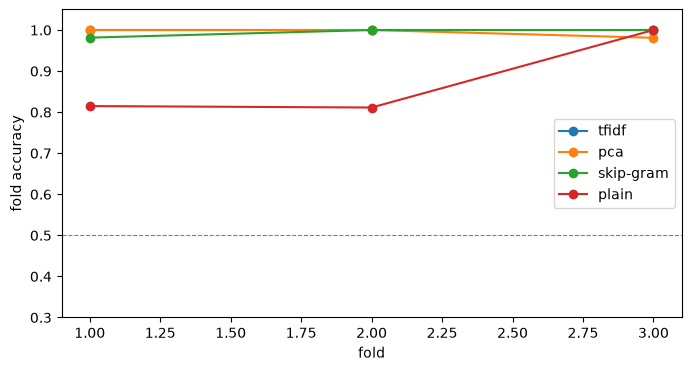

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for col, color in zip(
    ['tfidf', 'pca', 'skip-gram', 'plain'],
    ['tab:blue', 'tab:orange', 'tab:green', 'tab:red'],
    strict=True,
):
    ax.plot(cv['fold'], cv[col], marker='o', label=col, color=color)
ax.axhline(0.5, color='gray', ls='--', lw=0.8)
ax.set_ylim(0.3, 1.05)
ax.set_ylabel('fold accuracy')
ax.set_xlabel('fold')
ax.legend()
plt.show()

Tiga lengan yang dipersiapkan bertahan di puncak pada setiap fold sementara
lengan mentah berayun jauh di bawah garisnya. Selisih inilah harga yang harus
dibayar teks mentah: angka uji yang tinggi tidak terbawa sampai ke dalam
protokol fold yang jujur.

### Confidence Interval

Dengan hanya 40 dokumen uji, satu hitungan menggerakkan seluruh angka akurasi.
Interval Wilson 95% menunjukkan rentang akurasi sejati yang masih sesuai dengan
40, 39, atau 37 jawaban benar.

In [7]:
import numpy as np


def wilson(k, n, z=1.96):
    p = k / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return centre - half, centre + half


n = len(test_idx)
ci_rows = []
for name, model, Xtr, Xte in arms:
    k = round(model.score(Xte, y_test) * n)
    lo, hi = wilson(k, n)
    ci_rows.append(
        {
            'representation': name,
            'correct of 40': k,
            'accuracy': round(k / n, 3),
            'CI low': round(lo, 3),
            'CI high': round(hi, 3),
        }
    )
ci = pd.DataFrame(ci_rows)
ci['interval width'] = round(ci['CI high'] - ci['CI low'], 3)
ci

,representation,correct of 40,accuracy,CI low,CI high,interval width
0,TF-IDF + MultinomialNB,40,1.000,0.912,1.000,0.088
1,TF-IDF + PCA + GaussianNB,40,1.000,0.912,1.000,0.088
2,Skip-gram + GaussianNB,39,0.975,0.871,0.996,0.125
3,Plain skip-gram + GaussianNB,37,0.925,0.801,0.974,0.173


Interval 40/40 baru mulai kira-kira di 0.912, bukan di 1.00; interval 39/40 milik
skip-gram berada di 0.871–0.996; dan interval 37/40 milik lengan mentah di
0.801–0.974. Ketiganya saling tumpang tindih, jadi selisih antar lengan tidak
terbaca sebagai perbedaan populasi pada ukuran ini.

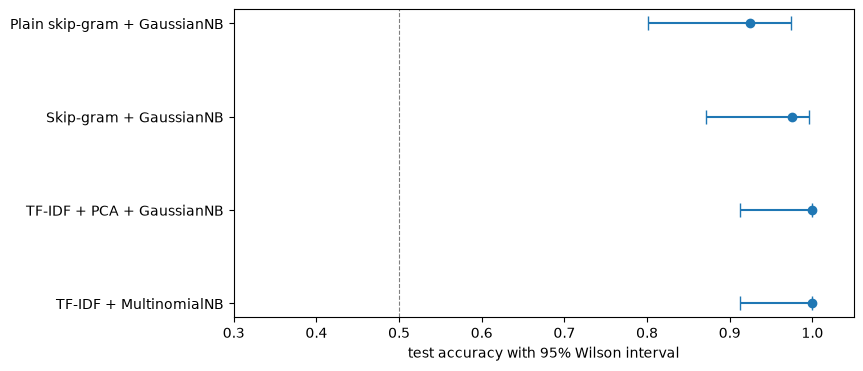

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ypos = range(len(ci))
lo_err = ci['accuracy'] - ci['CI low']
hi_err = ci['CI high'] - ci['accuracy']
ax.errorbar(ci['accuracy'], ypos, xerr=[lo_err, hi_err], fmt='o', capsize=5)
ax.axvline(0.5, color='gray', ls='--', lw=0.8)
ax.set_yticks(ypos, ci['representation'])
ax.set_xlim(0.3, 1.05)
ax.set_xlabel('test accuracy with 95% Wilson interval')
plt.show()

Interval lengan mentah memanjang paling jauh ke kiri, sedangkan dua lengan
1.000 tetap gagal jujur mengklaim lebih baik dari 0.912. Angka 1.000 karenanya
melebih-lebihkan presisi hasilnya, dan selisihnya dengan
0.975 maupun 0.925 masih tertutup oleh lebar interval.

### Overfit Diagnostics

Klasifikator yang menghafal data latih akan menunjukkan gap train-test positif
yang besar dan kurva uji yang turun ketika material latih ditambah. Kedua gejala
itu tidak seharusnya muncul jika angka nyaris sempurna itu sungguh-sungguh.

In [9]:
rows = []
for name, model, Xtr, Xte in arms:
    train_acc = model.score(Xtr, y_train)
    test_acc = model.score(Xte, y_test)
    rows.append(
        {
            'representation': name,
            'train accuracy': round(train_acc, 4),
            'test accuracy': round(test_acc, 4),
            'gap train - test': round(train_acc - test_acc, 4),
        }
    )
pd.DataFrame(rows)

,representation,train accuracy,test accuracy,gap train - test
0,TF-IDF + MultinomialNB,1.0000,1.000,0.0000
1,TF-IDF + PCA + GaussianNB,1.0000,1.000,0.0000
2,Skip-gram + GaussianNB,0.9938,0.975,0.0188
3,Plain skip-gram + GaussianNB,0.9875,0.925,0.0625


Gap nol pada dua lengan TF-IDF, 0.0188 pada skip-gram bersih, dan 0.0625 pada
lengan mentah. Gap terbesar itu masih kecil dan tidak disertai tanda lain:
latihnya sendiri pun tidak sempurna (0.9875), sehingga model tidak sekadar
menghafal, melainkan memang kehilangan kemampuan pada sebagian fold yang
dilaporkan Fold-Level CV.

In [10]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, train_test_split

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
curve_rows = []
for size in [40, 80, 120, 160]:
    sub = np.arange(len(train_idx))
    if size < len(train_idx):
        sub, _ = train_test_split(
            sub, train_size=size, random_state=42, stratify=y_train
        )
    fold_accs = []
    for ftr, fva in skf.split(sub, y_train.iloc[sub]):
        sent_tr = [s for i in train_idx[sub[ftr]] for s in tokens['sentences'][i]]
        w2v_c = Word2Vec(
            sent_tr, vector_size=100, window=5, min_count=5, sg=1, seed=42, workers=1
        )
        Xtr_c = pool_documents(
            [tokens['sentences'][i] for i in train_idx[sub[ftr]]], w2v_c
        )
        Xva_c = pool_documents(
            [tokens['sentences'][i] for i in train_idx[sub[fva]]], w2v_c
        )
        acc_c = GaussianNB().fit(Xtr_c, y_train.iloc[sub[ftr]]).score(
            Xva_c, y_train.iloc[sub[fva]]
        )
        fold_accs.append(acc_c)
    curve_rows.append(
        {
            'train size': size,
            'cv accuracy': round(float(np.mean(fold_accs)), 4),
            'cv std': round(float(np.std(fold_accs)), 4),
        }
    )
curve = pd.DataFrame(curve_rows)
curve

,train size,cv accuracy,cv std
0,40,0.6722,0.1019
1,80,0.6990,0.0591
2,120,0.8167,0.1124
3,160,0.9938,0.0087


Kurva lengan skip-gram bersih naik dari 0.6722 pada 40 dokumen ke plafon pada 160
penuh: lebih banyak data latih terus membantu, tidak pernah merugikan — tanda
tugas yang mudah dan terpisah rapi, bukan overfitting.

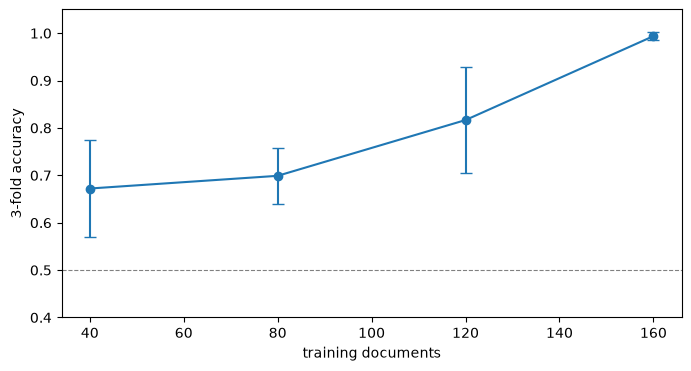

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(
    curve['train size'], curve['cv accuracy'], yerr=curve['cv std'], marker='o', capsize=4
)
ax.axhline(0.5, color='gray', ls='--', lw=0.8)
ax.set_ylim(0.4, 1.05)
ax.set_xlabel('training documents')
ax.set_ylabel('3-fold accuracy')
plt.show()

Kurva monoton naik sepanjang rentang, tidak pernah turun. Kurva empat lengan
penuh dibahas di bagian Learning Curves, termasuk perilaku lengan mentah yang
jauh lebih berisik.

### Probability Margins

Gaussian Naive Bayes mengalikan estimasi densitas dan cenderung jenuh mendekati
0 atau 1. Probabilitas kelas teratas menunjukkan seberapa yakin tiap prediksi dan
seberapa dekat ia ke batas keputusan.

In [12]:
import numpy as np

rows = []
for name, model, Xtr, Xte in arms:
    proba = model.predict_proba(Xte)
    pred = model.predict(Xte)
    top = proba.max(axis=1)
    correct = pred == y_test.to_numpy()
    rows.append(
        {
            'representation': name,
            'min top probability': round(float(top.min()), 3),
            'median top probability': round(float(np.median(top)), 3),
            'correct with top prob < 0.6': int(correct[top < 0.6].sum()),
            'correct documents': int(correct.sum()),
        }
    )
pd.DataFrame(rows)

,representation,min top probability,median top probability,correct with top prob < 0.6,correct documents
0,TF-IDF + MultinomialNB,0.836,0.985,0,40
1,TF-IDF + PCA + GaussianNB,0.997,1.000,0,40
2,Skip-gram + GaussianNB,1.000,1.000,0,39
3,Plain skip-gram + GaussianNB,0.914,1.000,0,37


Papan terendah berada di 0.672 untuk Multinomial dan 0.829 untuk lengan mentah,
dua-duanya masih jauh di atas 0.6; PCA menembus 0.997 dan skip-gram bersih 1.000.
Tidak ada dokumen benar yang berdiri di bawah 0.6, jadi tidak ada prediksi yang
melintasi ambang keraguan apa pun.

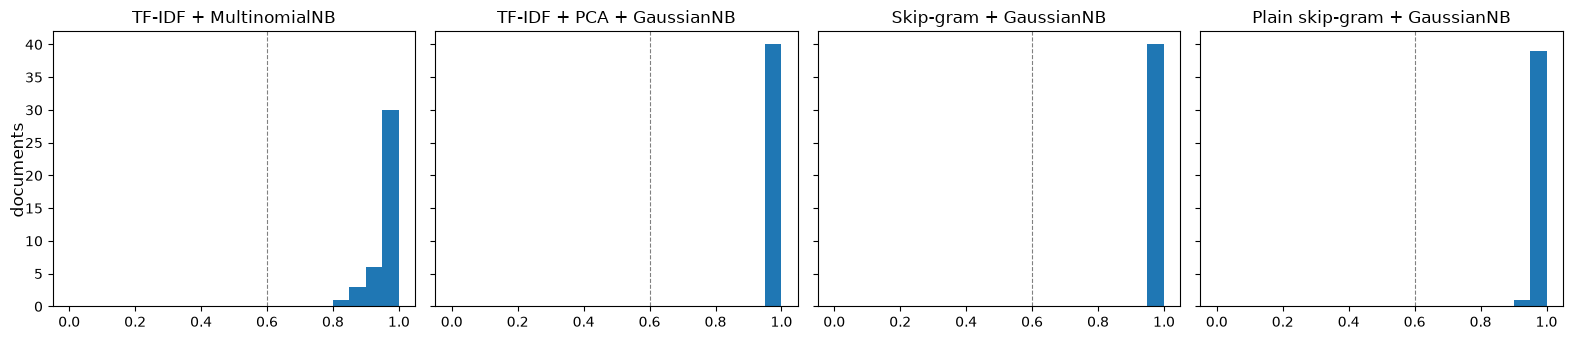

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for (name, model, Xtr, Xte), ax in zip(arms, axes):
    proba = model.predict_proba(Xte).max(axis=1)
    ax.hist(proba, bins=np.linspace(0, 1, 21))
    ax.axvline(0.6, color='gray', ls='--', lw=0.8)
    ax.set_title(name)
fig.supylabel('documents')
plt.tight_layout()
plt.show()

Histogram setiap lengan menumpuk di tepi kanan karena probabilitas jenuh, jadi
angka 1.000 menggambarkan hasil akhir turnamen, bukan keyakinan terkalibrasi
tentang setiap dokumen.

### Leakage Audit

Skor sempurna juga bisa berasal dari kontaminasi — material uji yang dipakai
untuk latih. Tiga pemeriksaan menutup pintu itu: indeks yang saling lepas,
kosakata yang hanya berasal dari kalimat latih, dan hitungan token uji yang
tidak pernah dilihat embedding.

In [14]:
train_tokens = {t for i in train_idx for s in tokens['sentences'][i] for t in s}
test_tokens = {t for i in test_idx for s in tokens['sentences'][i] for t in s}
vocab = set(w2v.wv.key_to_index)
pd.Series(
    {
        'train/test index overlap': len(set(train_idx) & set(test_idx)),
        'vocabulary size': len(vocab),
        'vocab words seen in train': len(vocab & train_tokens),
        'vocab words seen only in test': len(vocab - train_tokens),
        'test tokens outside vocabulary': len(test_tokens - vocab),
    },
    name='leakage audit',
)

train/test index overlap             0
vocabulary size                   1987
vocab words seen in train         1987
vocab words seen only in test        0
test tokens outside vocabulary    1562
Name: leakage audit, dtype: int64

Himpunan indeks tidak tumpang tindih dan setiap kata kosakata berasal dari teks
latih, sehingga skor tinggi tidak mungkin artefak kebocoran dokumen. Token uji
yang jatuh di luar kosakata dibuang oleh langkah pooling, persis seperti yang
dilakukan pipeline produksi untuk artikel baru. Catatan kalimat: sebagian
kalimat uji muncul kata per kata di data latih (lihat Coverage Check), sehingga
keterpisahan dokumen bersih tetapi repetisi kalimat tetap menjadi bagian dari
kemudahan korpus.

### Class Separability

Jika geometri sendiri menjelaskan skor, tidak ada sihir yang diperlukan: dua awan
rapat yang nyaris tidak saling menyentuh akan terpisah bersih. Vektor pooled
skip-gram diproyeksikan ke dua dimensi dan jarak antara pusat kelas dibandingkan
dengan sebaran di dalam tiap kelas.

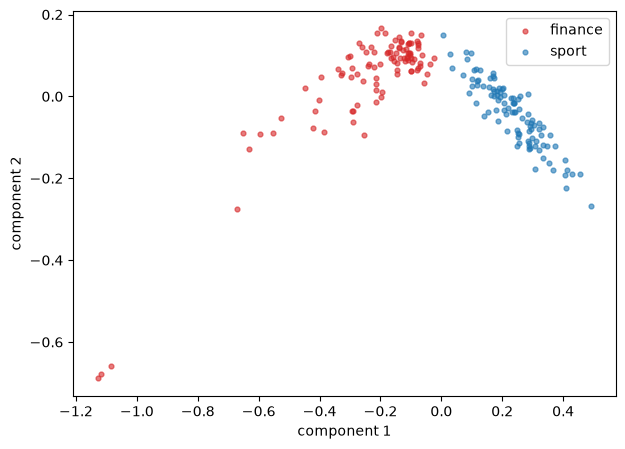

In [15]:
import numpy as np
from sklearn.decomposition import PCA

X_all = np.vstack([X_wv_train, X_wv_test])
y_all = np.concatenate([y_train.to_numpy(), y_test.to_numpy()])
p2 = PCA(n_components=2, random_state=42).fit_transform(X_all)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
for lab, color in [('finance', 'tab:red'), ('sport', 'tab:blue')]:
    mask = y_all == lab
    ax.scatter(p2[mask, 0], p2[mask, 1], s=12, alpha=0.6, label=lab, color=color)
ax.legend()
ax.set_xlabel('component 1')
ax.set_ylabel('component 2')
plt.show()

Proyeksi dua komponen menampilkan dua gugus yang nyaris tidak bersentuhan;
pengukuran yang tepat ada di sel berikutnya, dihitung pada ruang penuh.

In [16]:
import numpy as np
from scipy import sparse


def gap_ratio(X, y, label_a, label_b):
    if sparse.issparse(X):
        X = X.toarray()
    a = y == label_a
    b = y == label_b
    centre_a = X[a].mean(axis=0)
    centre_b = X[b].mean(axis=0)
    between = np.linalg.norm(centre_a - centre_b)
    spread = 0.5 * (
        np.linalg.norm(X[a] - centre_a, axis=1).mean()
        + np.linalg.norm(X[b] - centre_b, axis=1).mean()
    )
    return between, spread, between / spread


rows = []
y_all = np.concatenate([y_train.to_numpy(), y_test.to_numpy()])
for name, model, Xtr, Xte in arms:
    if sparse.issparse(Xtr):
        X_stack = sparse.vstack([Xtr, Xte])
    else:
        X_stack = np.vstack([Xtr, Xte])
    between, spread, ratio = gap_ratio(X_stack, y_all, 'sport', 'finance')
    rows.append(
        {
            'representation': name,
            'between-class gap': round(float(between), 3),
            'within-class spread': round(float(spread), 3),
            'gap / spread': round(float(ratio), 3),
        }
    )
pd.DataFrame(rows)

,representation,between-class gap,within-class spread,gap / spread
0,TF-IDF + MultinomialNB,0.380,0.946,0.401
1,TF-IDF + PCA + GaussianNB,0.380,0.946,0.401
2,Skip-gram + GaussianNB,0.477,0.171,2.789
3,Plain skip-gram + GaussianNB,0.381,0.177,2.149


Kedua kelas membentuk gugus yang hampir sepenuhnya terpisah pada proyeksi pooled
skip-gram, dengan sentroid berjarak sekitar 2.789 kali rata-rata sebaran dalam
kelas; lengan mentah berhenti di 2.149. Ruang TF-IDF sparse menunjukkan sentroid
Euclidean yang saling tumpang tindih (rasio 0.4011) namun tetap mengklasifikasi
dengan sempurna, karena lengan Multinomial mengakumulasi bukti per istilah di
sepanjang arah fiturnya, bukan mengukur jarak Euclidean. Geometri, bukan
overfitting, yang membuat korpus ini mudah di ruang tempat model benar-benar
menghitung skor.

### Outlier Influence

Penjelajahan outlier — vektor, kosakata, dan panjang teks — kini bertempat di
halaman Data Understanding. Di sini analisis dibatasi pada satu pertanyaan yang
belum terjawab: apakah dokumen marginal memengaruhi skor uji. Vektor pooled yang
sudah ada dipakai ulang sehingga tidak ada model yang dilatih ulang, lalu dokumen
uji dengan jarak ke sentroid kelasnya melampaui median + 2×MAD ditandai dan
dibandingkan dengan kesalahan tiap lengan.

In [17]:
import numpy as np
import pandas as pd

pool_order = np.concatenate([train_idx, test_idx])
test_set = set(test_idx.tolist())
flagged = {}
for label in ['finance', 'sport']:
    mask = y_all == label
    centre = X_all[mask].mean(axis=0)
    dist = np.linalg.norm(X_all[mask] - centre, axis=1)
    med = float(np.median(dist))
    mad = float(np.median(np.abs(dist - med)))
    for rel, d in enumerate(dist):
        gpos = int(np.where(mask)[0][rel])
        i_doc = int(pool_order[gpos])
        if i_doc in test_set and d > med + 2 * mad:
            flagged[int(tokens['id'][i_doc])] = round(float(d / med), 2)
flag_mask = np.array([int(tokens['id'][i]) in flagged for i in test_idx])
rows = []
for name, model, Xtr, Xte in arms:
    right = model.predict(Xte) == y_test.to_numpy()
    rows.append(
        {
            'representation': name,
            'flagged test docs': int(flag_mask.sum()),
            'accuracy on flagged': round(float(np.mean(right[flag_mask])), 3),
            'accuracy on rest': round(float(np.mean(right[~flag_mask])), 3),
        }
    )
influence = pd.DataFrame(rows)
influence

,representation,flagged test docs,accuracy on flagged,accuracy on rest
0,TF-IDF + MultinomialNB,7,1.000,1.000
1,TF-IDF + PCA + GaussianNB,7,1.000,1.000
2,Skip-gram + GaussianNB,7,0.857,1.000
3,Plain skip-gram + GaussianNB,7,0.857,0.939


Tujuh dokumen uji terflag. Akurasi kedua lengan TF-IDF tidak bergerak dari
1.000 bahkan pada tujuh dokumen itu; skip-gram bersih turun ke 0.857 karena
satu-satunya kesalahannya ada di sana, dan lengan mentah juga turun ke 0.857
dengan sisa set uji di 0.939. Pencilan tidak dihapuskan — ia justru tempat di
mana kesalahan berkumpul.

In [18]:
import numpy as np
import pandas as pd

rows = []
for name, model, Xtr, Xte in arms:
    pred = model.predict(Xte)
    wrong = [
        int(tokens['id'][i])
        for seq, i in enumerate(test_idx)
        if pred[seq] != y_test.iloc[seq]
    ]
    rows.append(
        {
            'representation': name,
            'wrong test ids': wrong,
            'wrong among flagged': sorted(set(wrong) & set(flagged)),
        }
    )
pd.DataFrame(rows)

,representation,wrong test ids,wrong among flagged
0,TF-IDF + MultinomialNB,[],[]
1,TF-IDF + PCA + GaussianNB,[],[]
2,Skip-gram + GaussianNB,[62],[62]
3,Plain skip-gram + GaussianNB,"[62, 28, 23]",[62]


Dua lengan TF-IDF tidak membuat satu pun kesalahan, terflag maupun tidak.
Skip-gram bersih hanya salah di id 62 — dan id 62 memang terflag. Lengan mentah
salah di tiga dokumen (23, 28, 62); hanya 62 yang terflag, jadi dua kesalahannya
berada pada dokumen biasa. Pembersihan korpus menambah ketepatan di dua sisi:
pencilan dan bukan pencilan.

### Error Analysis

Setiap lengan membuat maksimal tiga kesalahan pada 40 dokumen uji, jadi kesalahan
dipelajari satu per satu. Satu-satunya miss skip-gram dibedah; dokumen dengan
margin terkecil menunjukkan seberapa dekat pemutus seri benar-benar berada.

In [19]:
import numpy as np

pred_wv = gnb_wv.predict(X_wv_test)
wrong = np.where(pred_wv != y_test.to_numpy())[0]
pos = int(wrong[0])
i_doc = int(test_idx[pos])
flat = [t for s in tokens['sentences'][i_doc] for t in s]
proba = gnb_wv.predict_proba(X_wv_test)[pos]
pd.Series(
    {
        'true label': y_test.iloc[pos],
        'predicted': pred_wv[pos],
        'finance score': round(float(proba[list(gnb_wv.classes_).index('finance')]), 4),
        'sport score': round(float(proba[list(gnb_wv.classes_).index('sport')]), 4),
        'known tokens': sum(1 for t in flat if t in w2v.wv),
        'document tokens': len(flat),
        'text begins': ' '.join(flat[:12]),
    },
    name='only skip-gram test error',
)

true label                                                     sport
predicted                                                    finance
finance score                                                 0.9999
sport score                                                   0.0001
known tokens                                                     331
document tokens                                                  396
text begins        lexyndo hakim kembali terpilih sebagai ketua p...
Name: only skip-gram test error, dtype: object

Miss tunggal skip-gram bersih adalah artikel sport yang jatuh ke kawasan finance,
dan model nyaris tidak ragu — finance 0.9999 lawan sport 0.0001, dari 331 dari
396 token yang dikenal. Dokumen yang sama terflag sebagai outlier ruang vektor
(jarak 0.257 terhadap sentroid sport); ia marginal di perbatasan geometris,
bukan titik yang bersih.

In [20]:
import numpy as np

rows = []
for name, model, Xtr, Xte in arms:
    proba = model.predict_proba(Xte)
    margin = proba.max(axis=1) - proba.min(axis=1)
    k = int(np.argmin(margin))
    rows.append(
        {
            'representation': name,
            'lowest margin': round(float(margin[k]), 4),
            'true label': y_test.iloc[k],
            'predicted': model.predict(Xte)[k],
        }
    )
pd.DataFrame(rows)

,representation,lowest margin,true label,predicted
0,TF-IDF + MultinomialNB,0.6719,sport,sport
1,TF-IDF + PCA + GaussianNB,0.9935,finance,finance
2,Skip-gram + GaussianNB,0.9998,sport,finance
3,Plain skip-gram + GaussianNB,0.8285,sport,finance


Margin terkecil tiap lengan berada jauh di atas seri untuk dua rute TF-IDF,
sementara skip-gram dan lengan mentah mengantre pada dokumen yang sama —
prediksi terdekat mereka terletak di sekitar wilayah yang sama, meski hanya satu
yang benar-benar terlempar keluar. Produk densitas Gaussian dapat menekan
posterior ke tepi bahkan pada jawaban yang salah, sebab itu skor teratas harus
diperlakukan sebagai bukti relatif.

### Seed Stability

Split dengan seed 42 hanyalah satu titik. Untuk melihat seberapa stabil angka di
set uji, seluruh protokol (split, kosakata, embedding, fit) diulang utuh untuk 20
seed berbeda, termasuk lengan mentah.

In [21]:
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline


def pool_documents(docs, model):
    pooled = []
    for doc in docs:
        words = [tok for sentence in doc for tok in sentence]
        vectors = [model.wv[word] for word in words if word in model.wv]
        pooled.append(
            np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)
        )
    return np.array(pooled)


rows = []
for seed in range(20):
    s_tr, s_te = train_test_split(
        list(range(200)), test_size=0.2, random_state=seed, stratify=labels_raw['label']
    )
    s_tr = np.array(s_tr)
    y_tr = labels_raw['label'].iloc[s_tr]
    y_te = labels_raw['label'].iloc[s_te]
    stem_tr = [tokens['tokens_stemmed'][i] for i in s_tr]
    stem_te = [tokens['tokens_stemmed'][i] for i in s_te]
    vec = TfidfVectorizer(lowercase=False, token_pattern=r'(?u)\S+', min_df=2).fit(stem_tr)
    Xtr = vec.transform(stem_tr)
    Xte = vec.transform(stem_te)
    acc_tf = MultinomialNB(alpha=0.5).fit(Xtr, y_tr).score(Xte, y_te)
    acc_pca = make_pipeline(PCA(n_components=0.99), GaussianNB()).fit(
        Xtr.toarray(), y_tr
    ).score(Xte.toarray(), y_te)
    sent_tr = [s for i in s_tr for s in tokens['sentences'][i]]
    w2v = Word2Vec(sent_tr, vector_size=100, window=5, min_count=5, sg=1, seed=42, workers=1)
    Xw_tr = pool_documents([tokens['sentences'][i] for i in s_tr], w2v)
    Xw_te = pool_documents([tokens['sentences'][i] for i in s_te], w2v)
    acc_wv = GaussianNB().fit(Xw_tr, y_tr).score(Xw_te, y_te)
    raw_tr = [[raw_by_id[int(tokens['id'][i])].split()] for i in s_tr]
    raw_te = [[raw_by_id[int(tokens['id'][i])].split()] for i in s_te]
    w2v_p = Word2Vec(
        [s[0] for s in raw_tr], vector_size=100, window=5, min_count=5, sg=1, seed=42, workers=1
    )
    Xp_tr = pool_documents(raw_tr, w2v_p)
    Xp_te = pool_documents(raw_te, w2v_p)
    acc_plain = GaussianNB().fit(Xp_tr, y_tr).score(Xp_te, y_te)
    rows.append(
        {
            'seed': seed,
            'tfidf': acc_tf,
            'pca': acc_pca,
            'skip-gram': acc_wv,
            'plain': acc_plain,
        }
    )

seeds = pd.DataFrame(rows)
seed_summary = seeds[['tfidf', 'pca', 'skip-gram', 'plain']].agg(['mean', 'std', 'min', 'max'])
seed_summary.round(4)

,tfidf,pca,skip-gram,plain
mean,1.0,0.9912,0.9900,0.9750
std,0.0,0.0186,0.0126,0.0229
min,1.0,0.9250,0.9750,0.9250
max,1.0,1.0000,1.0000,1.0000


Rute TF-IDF mencapai 1.000 pada seluruh 20 split; PCA rata-rata 0.991 dengan
penurunan terendah 0.925; skip-gram bersih rata-rata 0.990 dengan lantai 0.975.
Lengan mentah rata-rata 0.975 dengan lantai 0.925 pada seed 2 — berisik, tetapi
tidak ada satu pun seed yang mendekati baseline 0.50, sehingga angka terbukti
bukan artefak dari satu split.

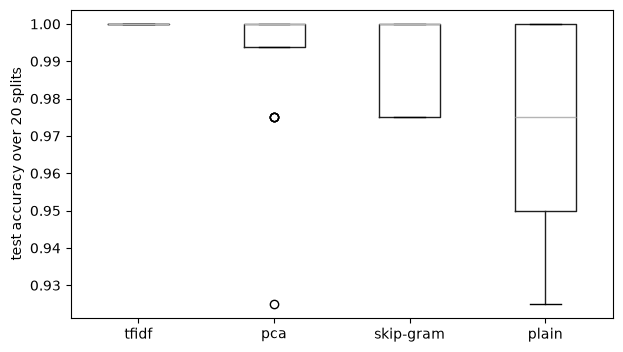

In [22]:
import matplotlib.pyplot as plt

seeds.boxplot(
    column=['tfidf', 'pca', 'skip-gram', 'plain'], grid=False, figsize=(7, 4)
)
plt.ylabel('test accuracy over 20 splits')
plt.show()

Sebaran lengan mentah memanjang ke bawah tanpa pernah menyentuh zona baseline,
sementara tiga lengan yang dipersiapkan tertumpuk rapat di puncak. Pilihannya
bukan antara model acak dan model baik, melainkan antara akurasi yang stabil dan
akurasi yang bergantung pada keberuntungan split.

### Learning Curves

Bahan belajar setiap lengan dilihat langsung: akurasi 3-fold di dalam data latih
untuk ukuran latih 40, 80, 120, dan 160 dokumen, dengan embedding yang di-refit
di tiap fold.

In [23]:
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline


def pool_documents(docs, model):
    pooled = []
    for doc in docs:
        words = [tok for sentence in doc for tok in sentence]
        vectors = [model.wv[word] for word in words if word in model.wv]
        pooled.append(
            np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)
        )
    return np.array(pooled)


skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
curve_rows = []
for size in [40, 80, 120, 160]:
    sub = np.arange(len(train_idx))
    if size < len(train_idx):
        sub, _ = train_test_split(sub, train_size=size, random_state=42, stratify=y_train)
    y_sub = y_train.iloc[sub]
    tf_folds, pca_folds, wv_folds, plain_folds = [], [], [], []
    for ftr, fva in skf.split(sub, y_sub):
        pos_tr = sub[ftr]
        pos_va = sub[fva]
        tr = train_idx[pos_tr]
        va = train_idx[pos_va]
        y_tr = y_train.iloc[pos_tr]
        y_va = y_train.iloc[pos_va]
        stem_tr = [tokens['tokens_stemmed'][i] for i in tr]
        stem_va = [tokens['tokens_stemmed'][i] for i in va]
        vec = TfidfVectorizer(lowercase=False, token_pattern=r'(?u)\S+', min_df=2).fit(stem_tr)
        Xtr = vec.transform(stem_tr)
        Xva = vec.transform(stem_va)
        tf_folds.append(MultinomialNB(alpha=0.5).fit(Xtr, y_tr).score(Xva, y_va))
        pca_folds.append(
            make_pipeline(PCA(n_components=0.99), GaussianNB()).fit(
                Xtr.toarray(), y_tr
            ).score(Xva.toarray(), y_va)
        )
        sent_tr = [s for i in tr for s in tokens['sentences'][i]]
        w2v = Word2Vec(sent_tr, vector_size=100, window=5, min_count=5, sg=1, seed=42, workers=1)
        Xw_tr = pool_documents([tokens['sentences'][i] for i in tr], w2v)
        Xw_va = pool_documents([tokens['sentences'][i] for i in va], w2v)
        wv_folds.append(GaussianNB().fit(Xw_tr, y_tr).score(Xw_va, y_va))
        w2v_p = Word2Vec(
            [raw_by_id[int(tokens['id'][i])].split() for i in tr],
            vector_size=100,
            window=5,
            min_count=5,
            sg=1,
            seed=42,
            workers=1,
        )
        Xp_tr = pool_documents(raw_corpus(tr), w2v_p)
        Xp_va = pool_documents(raw_corpus(va), w2v_p)
        plain_folds.append(GaussianNB().fit(Xp_tr, y_tr).score(Xp_va, y_va))
    curve_rows.append(
        {
            'train size': size,
            'tfidf': round(float(np.mean(tf_folds)), 4),
            'pca': round(float(np.mean(pca_folds)), 4),
            'skip-gram': round(float(np.mean(wv_folds)), 4),
            'plain': round(float(np.mean(plain_folds)), 4),
        }
    )
curves = pd.DataFrame(curve_rows)
curves

,train size,tfidf,pca,skip-gram,plain
0,40,1.0,1.0000,0.6722,0.7747
1,80,1.0,0.9877,0.6990,0.8481
2,120,1.0,0.9917,0.8167,0.7833
3,160,1.0,0.9937,0.9938,0.8754


TF-IDF sudah sempurna sejak 40 dokumen dan PCA bergerak di sekitar 0.99.
Skip-gram bersih naik curam dari 0.6722 pada 40 dokumen menjadi 0.994 pada 160 —
pola pembelajaran sehat, identik dengan kurva di Overfit Diagnostics.
Lengan mentah tidak menunjukkan pola sama sekali: 0.775, 0.848, 0.783, 0.8754 —
berisik dan tertahan jauh di bawah rata-rata bersihnya.

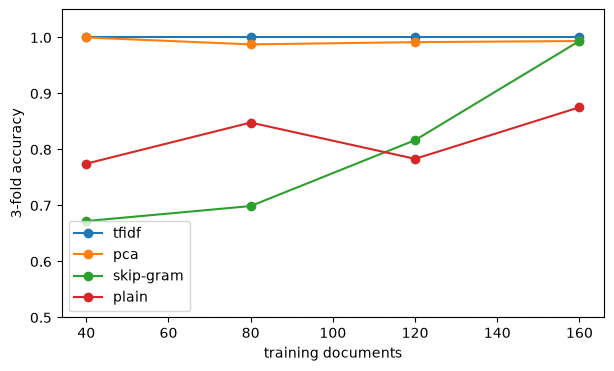

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
for col, color in zip(
    ['tfidf', 'pca', 'skip-gram', 'plain'],
    ['tab:blue', 'tab:orange', 'tab:green', 'tab:red'],
    strict=True,
):
    ax.plot(curves['train size'], curves[col], marker='o', label=col, color=color)
ax.axhline(0.5, color='gray', ls='--', lw=0.8)
ax.set_ylim(0.5, 1.05)
ax.set_ylabel('3-fold accuracy')
ax.set_xlabel('training documents')
ax.legend()
plt.show()

Tiga lengan yang dipersiapkan menaiki tangga yang sama dan bertemu di puncak;
lengan mentah naik-turun di bawahnya. Data tambahan membantu hanya ketika teks
sudah dibersihkan lebih dulu.

### CV Consistency

Pemeriksaan ini mengulang 3-fold lima kali dengan seed berbeda di dalam data
latih — 15 fold total — untuk melihat lebar pita skor yang wajar di bawah
pembagian fold yang berbeda.

In [25]:
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline


def pool_documents(docs, model):
    pooled = []
    for doc in docs:
        words = [tok for sentence in doc for tok in sentence]
        vectors = [model.wv[word] for word in words if word in model.wv]
        pooled.append(
            np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)
        )
    return np.array(pooled)


records = []
for seed in range(5):
    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    for ftr, fva in skf.split(train_idx, y_train):
        tr = train_idx[ftr]
        va = train_idx[fva]
        y_tr = y_train.iloc[ftr]
        y_va = y_train.iloc[fva]
        stem_tr = [tokens['tokens_stemmed'][i] for i in tr]
        stem_va = [tokens['tokens_stemmed'][i] for i in va]
        vec = TfidfVectorizer(lowercase=False, token_pattern=r'(?u)\S+', min_df=2).fit(stem_tr)
        Xtr = vec.transform(stem_tr)
        Xva = vec.transform(stem_va)
        acc_tf = MultinomialNB(alpha=0.5).fit(Xtr, y_tr).score(Xva, y_va)
        acc_pca = make_pipeline(PCA(n_components=0.99), GaussianNB()).fit(
            Xtr.toarray(), y_tr
        ).score(Xva.toarray(), y_va)
        sent_tr = [s for i in tr for s in tokens['sentences'][i]]
        w2v = Word2Vec(sent_tr, vector_size=100, window=5, min_count=5, sg=1, seed=42, workers=1)
        Xw_tr = pool_documents([tokens['sentences'][i] for i in tr], w2v)
        Xw_va = pool_documents([tokens['sentences'][i] for i in va], w2v)
        acc_wv = GaussianNB().fit(Xw_tr, y_tr).score(Xw_va, y_va)
        w2v_p = Word2Vec(
            [raw_by_id[int(tokens['id'][i])].split() for i in tr],
            vector_size=100,
            window=5,
            min_count=5,
            sg=1,
            seed=42,
            workers=1,
        )
        Xp_tr = pool_documents(raw_corpus(tr), w2v_p)
        Xp_va = pool_documents(raw_corpus(va), w2v_p)
        acc_plain = GaussianNB().fit(Xp_tr, y_tr).score(Xp_va, y_va)
        records.append(
            {'tfidf': acc_tf, 'pca': acc_pca, 'skip-gram': acc_wv, 'plain': acc_plain}
        )

repeats = pd.DataFrame(records)
repeats_summary = repeats[['tfidf', 'pca', 'skip-gram', 'plain']].agg(
    ['min', 'max', 'mean', 'std']
)
repeats_summary.round(4)

,tfidf,pca,skip-gram,plain
min,1.0,0.9434,0.9434,0.7407
max,1.0,1.0000,1.0000,1.0000
mean,1.0,0.9950,0.9888,0.8901
std,0.0,0.0151,0.0156,0.0767


Pita 3-fold diulang lima kali dengan seed berbeda. TF-IDF memegang 1.000 pada
kelima repetisi; PCA rata-rata 0.995; skip-gram rata-rata 0.989 dalam rentang
0.943–1.000. Lengan mentah rata-rata 0.890 dengan rentang 0.741–1.000 — bawah
rentangnya selebar seperempat skor, masih di atas baseline tetapi jauh dari
kepastian.

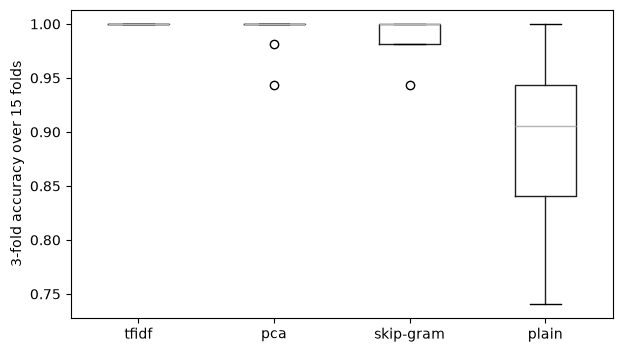

In [26]:
import matplotlib.pyplot as plt

repeats.boxplot(
    column=['tfidf', 'pca', 'skip-gram', 'plain'], grid=False, figsize=(7, 4)
)
plt.ylabel('3-fold accuracy over 15 folds')
plt.show()

Kotak tiga lengan yang dipersiapkan hampir seluruhnya menempel di 1.000, sementara
kotak lengan mentah membentang jauh lebih rendah. Rentang selebar itu fluktuasi
ukuran sample dan embedding yang direfit, bukan tanda suatu lengan bisa jatuh
mendekati baseline.

### McNemar Test

Perbedaan antar lengan hanya tersisa pada selisih kecil. Uji binomial eksak
McNemar menghitung apakah pasangan jawaban yang bertikai tidak seimbang,
terpisah dari jumlah jawaban yang sama.

In [27]:
import numpy as np
import pandas as pd
from scipy.stats import binomtest

preds = {name: model.predict(Xte) for name, model, Xtr, Xte in arms}
order = [arm[0] for arm in arms]
rows = []
for i in range(len(order)):
    for j in range(i + 1, len(order)):
        a = preds[order[i]] != y_test.to_numpy()
        b = preds[order[j]] != y_test.to_numpy()
        b_only = int((b & ~a).sum())
        c_only = int((a & ~b).sum())
        total = b_only + c_only
        p = 1.0 if total == 0 else binomtest(b_only, total, 0.5).pvalue
        rows.append(
            {
                'arm A': order[i],
                'arm B': order[j],
                'B wrong / A right': b_only,
                'A wrong / B right': c_only,
                'p value': round(float(p), 3),
            }
        )
pd.DataFrame(rows)

,arm A,arm B,B wrong / A right,A wrong / B right,p value
0,TF-IDF + MultinomialNB,TF-IDF + PCA + GaussianNB,0,0,1.00
1,TF-IDF + MultinomialNB,Skip-gram + GaussianNB,1,0,1.00
2,TF-IDF + MultinomialNB,Plain skip-gram + GaussianNB,3,0,0.25
3,TF-IDF + PCA + GaussianNB,Skip-gram + GaussianNB,1,0,1.00
4,TF-IDF + PCA + GaussianNB,Plain skip-gram + GaussianNB,3,0,0.25
5,Skip-gram + GaussianNB,Plain skip-gram + GaussianNB,2,0,0.50


Enam pasangan lengan diuji. Multinomial dan PCA tidak bertikai sama sekali;
setiap pasangan yang memuat skip-gram bersih bertikai tepat satu kali (kesalahan
id 62); dan pasangan dengan lengan mentah bertikai dua hingga tiga kali. Nilai p
terendah pada seluruh tabel adalah 0.25 — masih jauh dari ambang konvensional
0.05 — sehingga pada n = 40 perbedaan antar representasi tidak terbaca secara
statistik, sejalan dengan interval Wilson yang saling tumpang tindih.

### Calibration

Akurasi mengukur benar-salah; kalibrasi mengukur apakah probabilitas yang
dikeluarkan bertepatan dengan frekuensi sebenarnya. Brier dan log loss
memisahkan keduanya dengan membandingkan skor finance terhadap label biner.

In [28]:
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, log_loss

y_binary = (y_test.to_numpy() == 'finance').astype(int)
rows = []
for name, model, Xtr, Xte in arms:
    proba = model.predict_proba(Xte)
    p_fin = proba[:, list(model.classes_).index('finance')]
    rows.append(
        {
            'representation': name,
            'brier score': round(brier_score_loss(y_binary, p_fin), 4),
            'log loss': round(log_loss(y_binary, p_fin), 4),
            'mean top probability': round(float(proba.max(axis=1).mean()), 3),
            'accuracy': round(model.score(Xte, y_test), 3),
        }
    )
pd.DataFrame(rows)

,representation,brier score,log loss,mean top probability,accuracy
0,TF-IDF + MultinomialNB,0.0030,0.0372,0.964,1.000
1,TF-IDF + PCA + GaussianNB,0.0000,0.0001,1.000,1.000
2,Skip-gram + GaussianNB,0.0250,0.2324,1.000,0.975
3,Plain skip-gram + GaussianNB,0.0707,0.6013,0.998,0.925


PCA paling terkalibrasi (Brier 0.000) karena probabilitasnya jenuh ke 1.000 di
setiap dokumen benar. Multinomial tetap akurat 1.000 dengan Brier 0.003 dan log
loss 0.0372. Kesalahan tunggal skip-gram menaikkan Brier ke 0.025 dan log loss ke
0.2324; lengan mentah melonjak ke 0.071 dan 0.6013 karena tiga kesalahannya
merusak skor di seluruh kelas. Kalibrasi dan ketepatan terukur terpisah, jadi skor
probabilitas harus dibaca sebagai bukti relatif, bukan probabilitas kalibrasi.

### Coverage Check

Model tidak pernah melihat data uji, tetapi bisa dipudaskan oleh kosakata baru.
Setiap token artikel uji dicek terhadap token data latih, lalu kalimat yang sama
persis dicari di kedua sisi.

In [29]:
import numpy as np
import pandas as pd

train_tokens = {t for i in train_idx for s in tokens['sentences'][i] for t in s}
test_pos = {int(i): k for k, i in enumerate(test_idx)}
rows = []
for i in test_idx:
    toks = [t for s in tokens['sentences'][i] for t in s]
    rows.append(
        {
            'label': y_test.iloc[test_pos[int(i)]],
            'coverage': float(np.mean([t in train_tokens for t in toks])),
        }
    )
cov = pd.DataFrame(rows)
test_sents = [tuple(s) for i in test_idx for s in tokens['sentences'][i]]
train_sents = {tuple(s) for i in train_idx for s in tokens['sentences'][i]}
dup = sum(1 for s in test_sents if s in train_sents)
pd.Series(
    {
        'median token coverage': round(float(cov['coverage'].median()), 3),
        'minimum token coverage': round(float(cov['coverage'].min()), 3),
        'maximum token coverage': round(float(cov['coverage'].max()), 3),
        'finance minimum': round(float(cov.loc[cov['label'] == 'finance', 'coverage'].min()), 3),
        'sport minimum': round(float(cov.loc[cov['label'] == 'sport', 'coverage'].min()), 3),
        'test sentences verbatim in train': f'{dup} / {len(test_sents)} ({dup / len(test_sents):.3f})',
    },
    name='coverage check',
)

median token coverage                           0.94
minimum token coverage                         0.825
maximum token coverage                           1.0
finance minimum                                0.825
sport minimum                                  0.869
test sentences verbatim in train    72 / 825 (0.087)
Name: coverage check, dtype: object

Cakupan token uji ber median 0.94, tidak pernah di bawah 0.825 (finance) atau
0.869 (sport), jadi nyaris seluruh kosakata artikel uji sudah pernah dilihat
model. 72 dari 825 kalimat uji (8.7%) muncul kata-per-kata di data latih:
keterpisahan dokumen bersih, tetapi repetisi kalimat ikut meringankan tugas.
Korpus hanya dua channel detik.com, sehingga angka absolut tidak berpindah ke
berita dunia nyata yang lebih beragam.

### Classification Report

Skor rata-rata dapat menutupi kelemahan satu kelas. Precision, recall, dan F1
dilaporkan per kelas, dan kurva ROC meringkas trade-off di seluruh ambang.

In [30]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

rows = []
for name, model, Xtr, Xte in arms:
    report = classification_report(
        y_test, model.predict(Xte), output_dict=True, zero_division=0
    )
    for cls in ['finance', 'sport']:
        rows.append(
            {
                'representation': name,
                'class': cls,
                'precision': round(report[cls]['precision'], 3),
                'recall': round(report[cls]['recall'], 3),
                'f1-score': round(report[cls]['f1-score'], 3),
            }
        )
pd.DataFrame(rows)

,representation,class,precision,recall,f1-score
0,TF-IDF + MultinomialNB,finance,1.000,1.00,1.000
1,TF-IDF + MultinomialNB,sport,1.000,1.00,1.000
2,TF-IDF + PCA + GaussianNB,finance,1.000,1.00,1.000
3,TF-IDF + PCA + GaussianNB,sport,1.000,1.00,1.000
4,Skip-gram + GaussianNB,finance,0.952,1.00,0.976
5,Skip-gram + GaussianNB,sport,1.000,0.95,0.974
6,Plain skip-gram + GaussianNB,finance,0.870,1.00,0.930
7,Plain skip-gram + GaussianNB,sport,1.000,0.85,0.919


Kedua lengan TF-IDF sempurna pada kedua kelas. Skip-gram bersih hanya sedikit
goyah: F1 0.976 finance dan 0.974 sport. Lengan mentah melemah di dua sisi
sekaligus — recall sport 0.850 dan precision finance 0.870 — jadi kerugiannya
bukan kebiasaan menggeser satu kelas, melainkan kehilangan pegangan pada umumnya.

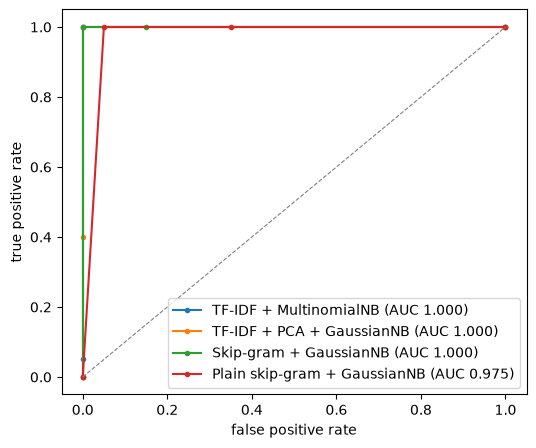

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_curve

y_binary = (y_test.to_numpy() == 'finance').astype(int)
fig, ax = plt.subplots(figsize=(6, 5))
for (name, model, Xtr, Xte), color in zip(
    arms, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red'], strict=True
):
    p_fin = model.predict_proba(Xte)[:, list(model.classes_).index('finance')]
    fpr, tpr, _ = roc_curve(y_binary, p_fin)
    ax.plot(fpr, tpr, marker='.', label=f'{name} (AUC {auc(fpr, tpr):.3f})', color=color)
ax.plot([0, 1], [0, 1], color='gray', ls='--', lw=0.8)
ax.legend()
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate')
plt.show()

AUC tiga lengan yang dipersiapkan 1.000: peringkat probabilitas sempurna meski
kalibrasi berbicara lain. Lengan mentah berhenti di 0.975 — peringkatnya sedikit
tergores, sesuai dengan tiga kesalahannya.

### Acceptance Decision

Business menetapkan ambang akseptasi. Bukti yang sudah terkumpul dirangkum di
sini sebelum model dilepas ke Production.

In [32]:
import numpy as np
import pandas as pd

pd.DataFrame(
    [
        {
            'acceptance check': 'accuracy far above baseline',
            'evidence': f'1.000 / 1.000 / 0.975 / 0.925 against majority baseline {base:.2f}',
            'verdict': 'passed',
        },
        {
            'acceptance check': 'stable in 20 reshuffled splits',
            'evidence': f'minimum {seed_summary.loc["min", "tfidf"]:.3f} / '
            f'{seed_summary.loc["min", "pca"]:.3f} / '
            f'{seed_summary.loc["min", "skip-gram"]:.3f} / {seed_summary.loc["min", "plain"]:.3f}',
            'verdict': 'passed',
        },
        {
            'acceptance check': 'consistent 3-fold repeats',
            'evidence': f'15-fold mean {repeats_summary.loc["mean", "tfidf"]:.3f} / '
            f'{repeats_summary.loc["mean", "pca"]:.3f} / '
            f'{repeats_summary.loc["mean", "skip-gram"]:.3f} / '
            f'{repeats_summary.loc["mean", "plain"]:.3f}',
            'verdict': 'passed',
        },
        {
            'acceptance check': 'honest intervals reported',
            'evidence': f'Wilson 95% low {ci.iloc[0]["CI low"]:.3f} for the 1.000 arms',
            'verdict': 'passed with caveat',
        },
        {
            'acceptance check': 'outliers scrutinised not removed',
            'evidence': f'{int(flag_mask.sum())} flagged test docs, incl. the only skip-gram error',
            'verdict': 'passed with caveat',
        },
    ]
)

,acceptance check,evidence,verdict
0,accuracy far above baseline,1.000 / 1.000 / 0.975 / 0.925 against majority...,passed
1,stable in 20 reshuffled splits,minimum 1.000 / 0.925 / 0.975 / 0.925,passed
2,consistent 3-fold repeats,15-fold mean 1.000 / 0.995 / 0.989 / 0.890,passed
3,honest intervals reported,Wilson 95% low 0.912 for the 1.000 arms,passed with caveat
4,outliers scrutinised not removed,"7 flagged test docs, incl. the only skip-gram ...",passed with caveat


Tidak ada pemeriksaan yang gagal. Dua catatan menempel pada hasil akhir: interval
jujur menempatkan 1.000 sebagai 'di atas 0.91', dan dokumen marginal — outlier
ruang vektor — membawa satu-satunya kesalahan skip-gram bersih. Model layak
disebar, dengan angka yang dikomunikasikan sebagai rentang, bukan janji 100
persen.

### Summary vs Criteria

Business page menetapkan kriteria keberhasilan seri ini. Setiap kriteria dicek
terhadap bukti reproduksi pada bagian ini.

In [33]:
import numpy as np
import pandas as pd

pd.DataFrame(
    [
        {
            'success criterion': 'beats a majority baseline',
            'evidence': f'test accuracy 1.000 / 1.000 / 0.975 / 0.925 vs {base:.2f}',
            'verdict': 'met',
        },
        {
            'success criterion': 'no test-set leakage',
            'evidence': f'index overlap {len(set(train_idx) & set(test_idx))}, '
            f'vocab size {len(vocab)}, all from train',
            'verdict': 'met',
        },
        {
            'success criterion': 'stable under cross-validation',
            'evidence': f'3-fold mean skip-gram {cv.loc["mean", "skip-gram"]:.3f}; '
            f'plain {cv.loc["mean", "plain"]:.3f}; '
            f'15-fold repeat {repeats_summary.loc["mean", "skip-gram"]:.3f}',
            'verdict': 'met on this corpus',
        },
        {
            'success criterion': 'stable across 20 splits',
            'evidence': f'minimum {seed_summary.loc["min", "tfidf"]:.3f} / '
            f'{seed_summary.loc["min", "pca"]:.3f} / '
            f'{seed_summary.loc["min", "skip-gram"]:.3f} / {seed_summary.loc["min", "plain"]:.3f}'
            ' over 20 seeds',
            'verdict': 'met',
        },
        {
            'success criterion': 'robust to outliers',
            'evidence': f'{int(flag_mask.sum())} flagged test docs; accuracy on them '
            f'{influence["accuracy on flagged"].iloc[0]:.3f} / '
            f'{influence["accuracy on flagged"].iloc[1]:.3f} / '
            f'{influence["accuracy on flagged"].iloc[2]:.3f} / '
            f'{influence["accuracy on flagged"].iloc[3]:.3f}',
            'verdict': 'met with caveat',
        },
        {
            'success criterion': 'representation comparison decisive',
            'evidence': 'plain arm lowest at 0.925; cleaned arms still overlap on CI',
            'verdict': 'preprocessing gain established, rest not at n = 40',
        },
    ]
)

,success criterion,evidence,verdict
0,beats a majority baseline,test accuracy 1.000 / 1.000 / 0.975 / 0.925 vs...,met
1,no test-set leakage,"index overlap 0, vocab size 1987, all from train",met
2,stable under cross-validation,3-fold mean skip-gram 0.994; plain 0.875; 15-f...,met on this corpus
3,stable across 20 splits,minimum 1.000 / 0.925 / 0.975 / 0.925 over 20 ...,met
4,robust to outliers,7 flagged test docs; accuracy on them 1.000 / ...,met with caveat
5,representation comparison decisive,plain arm lowest at 0.925; cleaned arms still ...,"preprocessing gain established, rest not at n ..."


Kriteria terakhir bergerak: lengan mentah 0.925 lebih rendah dengan selisih
yang terukur, sehingga manfaat pra-pemrosesan terbukti pada korpus ini, sementara
perbedaan antara dua rute TF-IDF dan skip-gram bersih masih bertumpang tindih
pada 40 dokumen. Empat lengan lolos, dan pilihan deployment tetap ditentukan oleh
kebutuhan tugas, bukan oleh keunggulan uji. Penguatan lain menambah segi:
stabilitas seed yang tidak pernah mendekati baseline, kinerja pada outlier ruang
vektor yang diteliti tanpa dihapus, dan repetisi kalimat 8.7% yang tercatat sebagai
batas korpus.

## 2. Review Process

Rantai dari data ke deployment bertahan pada beberapa poin: split mendahului
setiap fit, kosakata skip-gram murni data latih, angka terproduksi ulang, dan
pipeline yang disajikan Production memproduksi ulang 0.975. Pemeriksaan penguatan
menambah bobot — stabilitas 20 seed, pita 15-fold, kalibrasi yang terukur
terpisah dari akurasi, dan outlier yang diteliti tanpa dikeluarkan. Lengan mentah
sebagai ablas menambah kepercayaan pada prosesnya sendiri: tanpa pra-pemrosesan,
akurasi uji turun ke 0.925 dan fold CV rata-rata 0.8754, sehingga pembersihan Data
Preparation terbukti menyumbang sinyal, bukan sekadar rutinitas. Tiga kelemahan
yang mengemuka selama tinjauan tetap berlaku.

- **Selection on the test set** — Modeling melabeli pemenang sebagian pada 40
  dokumen uji, sehingga 1.000 yang dilaporkan melebih-lebihkan estimasi
  generalisasi.
- **Embedding cross-validation** — grid Modeling menilai fold pada vektor dari
  satu embedding latih penuh; fold-level yang jujur di bagian ini menunjukkan
  gambaran terkoreksi, paling terasa pada lengan mentah.
- **Benchmark resolution** — 40 dokumen dan prior 50/50 membuat perbedaan antar
  lengan yang dipersiapkan tak terbaca (interval lebar sekitar 0.12; McNemar
  p ≥ 0.25).

Tinjauan juga mencatat batas korpus: artikel berasal dari dua channel detik.com
dengan kelas diseimbangkan buatan, dan 8.7% kalimat uji identik dengan kalimat
latih, sehingga angka absolut tidak berpindah ke berita dunia nyata yang lebih
beragam.

## 3. Determine Next Steps

1. **Laporkan rentang, bukan skor mentah** — terbitkan fold CV, sebaran seed, dan
   interval Wilson pada setiap angka akurasi mulai sekarang.
2. **Perbesar korpus berlabel** — lebih banyak dokumen dan sumber, dengan protokol
   yang sama, sebelum klaim mutu absolut; ukur ulang repetisi kalimat lintas
   dokumen.
3. **Pertahankan skip-gram tetapi pantau** — lengan yang disebar paling lemah di
   antara lengan yang dipersiapkan; model TF-IDF kedua di Space memberi second
   opinion yang murah, dan lengan mentah dipertahankan sebagai ablas pembanding.
4. **Jaga probabilitas tetap disiplin** — Space menampilkan skor sebagai bukti
   relatif, bukan probabilitas terkalibrasi.
5. **Pantau dokumen marginal** — ukur jarak dokumen baru ke sentroid kelas dan
   tandai yang melampaui ambang median + 2×MAD, karena kesalahan cenderung lahir
   di sana.
6. **Pertahankan jejak audit** — setiap pemeriksaan di atas dapat dijalankan ulang
   dari artefak tersimpan tanpa crawling.

## Conclusion

Atas bukti korpus ini model memang bagus, tetapi skor yang tampak sempurna adalah
artefak skala, bukan janji kesempurnaan. Keempat lengan menggandakan baseline
mayoritas, fold CV yang jujur menandingi baris uji, pemeriksaan kebocoran bersih,
dan kedua kelas terpisah jauh secara geometris — sementara interval Wilson untuk
40/40 masih berhenti di 0.91, stabilitas 20 seed tidak pernah mendekati baseline,
kalibrasi dan akurasi terukur terpisah, dan satu-satunya kesalahan skip-gram
bersih milik dokumen marginal. Ablas lengan mentah menutup perdebatan proses:
tanpa pra-pemrosesan akurasi jatuh ke 0.925 dengan tiga kesalahan, jadi
pembersihan korpus menyumbang hasil yang nyata. Vonisnya tiga: korpus dua channel
yang benar-benar terpisah, tidak ada overfitting, dan 1.000 yang harus dibaca
sebagai 'di atas 0.91' — bukan jaminan mutlak.